# SL Telecom Churn – Ensemble Learning

MLPR hands-on project

Compare bagging / boosting / stacking on a Sri Lankan-style telecom churn dataset, and RF vs XGBoost. Dashboard is in `app.py`.

## 1. Setup

Uncomment pip if needed. Data is in `data/sl_telecom_churn.csv`.

In [1]:
# !pip install pandas numpy scikit-learn xgboost matplotlib seaborn joblib streamlit -q


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
)
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier,
    BaggingClassifier, StackingClassifier, VotingClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

# xgboost sometimes needs libomp on mac – fall back if needed
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception as e:
    print("couldn't import xgboost:", e)
    from sklearn.ensemble import HistGradientBoostingClassifier
    HAS_XGB = False

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
print("ready | xgboost:", HAS_XGB)


Matplotlib is building the font cache; this may take a moment.


ready | xgboost: True


## 2. Data

Couldn't get a real operator dump, so I generated a local-context set (Dialog/Mobitel/Hutch/Airtel, districts, LKR). Churn depends on tenure, bill, late payments, complaints etc.

In [3]:
from pathlib import Path
from make_dataset import build

data_path = Path("data/sl_telecom_churn.csv")
data_path.parent.mkdir(exist_ok=True)

if not data_path.exists():
    build(8000).to_csv(data_path, index=False)
    print("generated fresh dataset")

df = pd.read_csv(data_path)
print(df.shape)
df.head()


(8000, 16)


,customer_id,operator,district,plan_type,tenure_months,monthly_bill_lkr,data_usage_gb,call_minutes,late_payments_6m,avg_download_mbps,active_nights_last_month,last_complaint,payment_method,age,urban,churned
0,SL-03642,Airtel,Jaffna,Postpaid,53,875.03,13.8,1480,3,12.4,12,NaN,Card,25,0,0
1,SL-05087,Mobitel,Ratnapura,Prepaid,25,5286.14,76.3,357,5,79.3,8,Billing,eZ Cash,52,0,1
2,SL-01658,Mobitel,Batticaloa,Combo,45,6472.37,62.7,152,0,13.1,12,Speed,Card,54,0,1
3,SL-06843,Hutch,Negombo,Broadband,62,5281.01,11.5,1467,3,37.6,14,NaN,Card,67,1,1
4,SL-00789,Hutch,Matara,Broadband,23,6292.01,43.3,1705,7,55.0,18,NaN,eZ Cash,55,0,0


In [4]:
df.info()
print()
print("churn rate:", round(df.churned.mean(), 3))
print(df.churned.value_counts())


<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               8000 non-null   str    
 1   operator                  8000 non-null   str    
 2   district                  8000 non-null   str    
 3   plan_type                 8000 non-null   str    
 4   tenure_months             8000 non-null   int64  
 5   monthly_bill_lkr          8000 non-null   float64
 6   data_usage_gb             8000 non-null   float64
 7   call_minutes              8000 non-null   int64  
 8   late_payments_6m          8000 non-null   int64  
 9   avg_download_mbps         8000 non-null   float64
 10  active_nights_last_month  8000 non-null   int64  
 11  last_complaint            3612 non-null   str    
 12  payment_method            8000 non-null   str    
 13  age                       8000 non-null   int64  
 14  urban              

In [5]:
# quick sanity checks
print(df.operator.value_counts())
print()
print(df.groupby("operator")["churned"].mean().sort_values(ascending=False))


operator
Dialog     2986
Mobitel    2546
Hutch      1466
Airtel     1002
Name: count, dtype: int64

operator
Airtel     0.423154
Hutch      0.406548
Dialog     0.401875
Mobitel    0.379419
Name: churned, dtype: float64


## 3. EDA

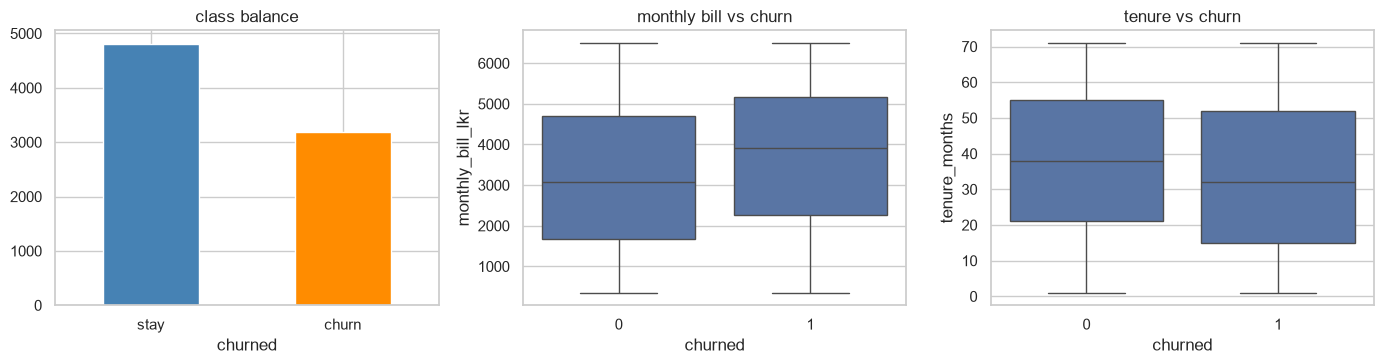

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

df.churned.value_counts().plot(kind="bar", ax=axes[0], color=["steelblue", "darkorange"])
axes[0].set_title("class balance")
axes[0].set_xticklabels(["stay", "churn"], rotation=0)

sns.boxplot(data=df, x="churned", y="monthly_bill_lkr", ax=axes[1])
axes[1].set_title("monthly bill vs churn")

sns.boxplot(data=df, x="churned", y="tenure_months", ax=axes[2])
axes[2].set_title("tenure vs churn")

plt.tight_layout()
plt.show()


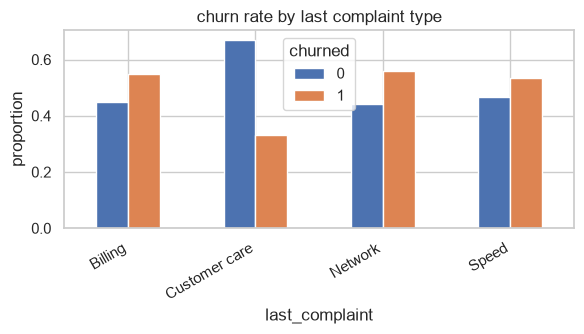

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
pd.crosstab(df["last_complaint"], df["churned"], normalize="index").plot(kind="bar", ax=ax)
ax.set_title("churn rate by last complaint type")
ax.set_ylabel("proportion")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# looks like Network / Billing / Speed complainers churn more — makes sense


## 4. Preprocess + split

In [8]:
CAT = ["operator", "district", "plan_type", "last_complaint", "payment_method"]
NUM = [
    "tenure_months", "monthly_bill_lkr", "data_usage_gb", "call_minutes",
    "late_payments_6m", "avg_download_mbps", "active_nights_last_month", "age", "urban"
]

X = df[CAT + NUM].copy()
y = df["churned"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape, "pos rate train:", y_train.mean().round(3))


(6400, 14) (1600, 14) pos rate train: 0.398


In [9]:
def make_pipe(clf):
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
        ("num", "passthrough", NUM),
    ])
    return Pipeline([("pre", pre), ("clf", clf)])


def eval_model(name, model):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    out = {
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, proba),
    }
    print(name)
    for k, v in out.items():
        if k != "model":
            print(f"  {k:10s}: {v:.4f}")
    print()
    return out, pred


## 5. Models

Bagging (RF), boosting (GB + XGBoost), stacking, soft voting.

In [10]:
results = []

# --- bagging ---
rf = make_pipe(RandomForestClassifier(
    n_estimators=150, max_depth=12, min_samples_leaf=3, random_state=42, n_jobs=-1
))
rf.fit(X_train, y_train)
r, rf_pred = eval_model("RandomForest", rf)
results.append(r)

bag = make_pipe(BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=8, random_state=42),
    n_estimators=40, random_state=42, n_jobs=-1
))
bag.fit(X_train, y_train)
r, _ = eval_model("Bagging(DT)", bag)
results.append(r)


RandomForest
  accuracy  : 0.6994
  precision : 0.6566
  recall    : 0.5133
  f1        : 0.5762
  roc_auc   : 0.7518



Bagging(DT)
  accuracy  : 0.6987
  precision : 0.6401
  recall    : 0.5557
  f1        : 0.5950
  roc_auc   : 0.7448



In [11]:
# --- boosting ---
gb = make_pipe(GradientBoostingClassifier(
    n_estimators=100, learning_rate=0.08, max_depth=3, random_state=42
))
gb.fit(X_train, y_train)
r, _ = eval_model("GradientBoosting", gb)
results.append(r)

if HAS_XGB:
    xgb_clf = XGBClassifier(
        n_estimators=120, max_depth=4, learning_rate=0.08,
        subsample=0.9, colsample_bytree=0.9,
        eval_metric="logloss", random_state=42, n_jobs=-1
    )
else:
    xgb_clf = HistGradientBoostingClassifier(
        max_depth=4, learning_rate=0.08, random_state=42
    )
    print("using HistGradientBoosting as XGB stand-in")

xgb = make_pipe(xgb_clf)
xgb.fit(X_train, y_train)
r, xgb_pred = eval_model("XGBoost" if HAS_XGB else "HistGB (XGB fallback)", xgb)
results.append(r)


GradientBoosting
  accuracy  : 0.6969
  precision : 0.6402
  recall    : 0.5447
  f1        : 0.5886
  roc_auc   : 0.7548

XGBoost
  accuracy  : 0.6944
  precision : 0.6341
  recall    : 0.5495
  f1        : 0.5887
  roc_auc   : 0.7512



In [12]:
# --- stacking + soft voting ---
stack = make_pipe(StackingClassifier(
    estimators=[
        ("rf", RandomForestClassifier(n_estimators=80, max_depth=10, random_state=42, n_jobs=-1)),
        ("gb", GradientBoostingClassifier(n_estimators=60, max_depth=3, random_state=42)),
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    n_jobs=-1,
))
stack.fit(X_train, y_train)
r, _ = eval_model("Stacking(RF+GB→LR)", stack)
results.append(r)

vote = make_pipe(VotingClassifier(
    estimators=[
        ("rf", RandomForestClassifier(n_estimators=80, max_depth=10, random_state=42, n_jobs=-1)),
        ("gb", GradientBoostingClassifier(n_estimators=60, max_depth=3, random_state=42)),
        ("lr", LogisticRegression(max_iter=1000)),
    ],
    voting="soft",
    n_jobs=-1,
))
vote.fit(X_train, y_train)
r, _ = eval_model("Voting soft", vote)
results.append(r)


Stacking(RF+GB→LR)
  accuracy  : 0.6937
  precision : 0.6354
  recall    : 0.5416
  f1        : 0.5847
  roc_auc   : 0.7548



Voting soft
  accuracy  : 0.6994
  precision : 0.6461
  recall    : 0.5416
  f1        : 0.5892
  roc_auc   : 0.7575



## 6. RF vs XGBoost

In [13]:
res_df = pd.DataFrame(results).sort_values("f1", ascending=False)
res_df


,model,accuracy,precision,recall,f1,roc_auc
1,Bagging(DT),0.698750,0.640145,0.555730,0.594958,0.744799
5,Voting soft,0.699375,0.646067,0.541601,0.589240,0.757542
3,XGBoost,0.694375,0.634058,0.549451,0.588730,0.751208
2,GradientBoosting,0.696875,0.640221,0.544741,0.588634,0.754771
4,Stacking(RF+GB→LR),0.693750,0.635359,0.541601,0.584746,0.754787
0,RandomForest,0.699375,0.656627,0.513344,0.576211,0.751762


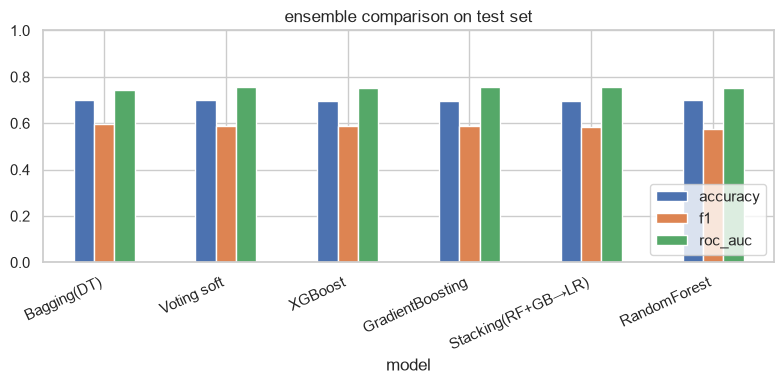

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_cols = ["accuracy", "f1", "roc_auc"]
res_df.set_index("model")[plot_cols].plot(kind="bar", ax=ax)
ax.set_ylim(0, 1)
ax.set_title("ensemble comparison on test set")
ax.legend(loc="lower right")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


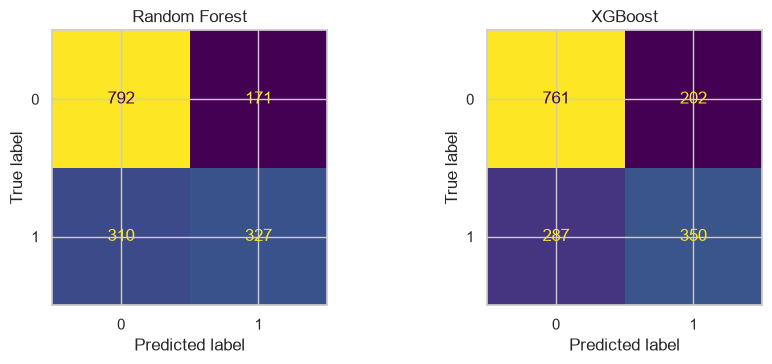

RF report
              precision    recall  f1-score   support

           0      0.719     0.822     0.767       963
           1      0.657     0.513     0.576       637

    accuracy                          0.699      1600
   macro avg      0.688     0.668     0.672      1600
weighted avg      0.694     0.699     0.691      1600

XGB report
              precision    recall  f1-score   support

           0      0.726     0.790     0.757       963
           1      0.634     0.549     0.589       637

    accuracy                          0.694      1600
   macro avg      0.680     0.670     0.673      1600
weighted avg      0.689     0.694     0.690      1600



In [15]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))

ConfusionMatrixDisplay(confusion_matrix(y_test, rf_pred)).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Random Forest")

ConfusionMatrixDisplay(confusion_matrix(y_test, xgb_pred)).plot(ax=axes[1], colorbar=False)
axes[1].set_title("XGBoost" if HAS_XGB else "HistGB fallback")

plt.tight_layout()
plt.show()

print("RF report")
print(classification_report(y_test, rf_pred, digits=3))
print("XGB report")
print(classification_report(y_test, xgb_pred, digits=3))


In [16]:
# 3-fold CV on train just for RF / XGB (f1) — sanity check that test scores aren't lucky
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

for name, model in [("RF", rf), ("XGB", xgb)]:
    # need fresh pipes for cv
    pass

rf_cv = make_pipe(RandomForestClassifier(
    n_estimators=150, max_depth=12, min_samples_leaf=3, random_state=42, n_jobs=-1
))
xgb_cv = make_pipe(
    XGBClassifier(
        n_estimators=120, max_depth=4, learning_rate=0.08,
        subsample=0.9, colsample_bytree=0.9,
        eval_metric="logloss", random_state=42, n_jobs=-1
    ) if HAS_XGB else HistGradientBoostingClassifier(max_depth=4, learning_rate=0.08, random_state=42)
)

for name, m in [("RF", rf_cv), ("XGB", xgb_cv)]:
    scores = cross_val_score(m, X_train, y_train, cv=cv, scoring="f1")
    print(f"{name} CV F1: {scores.mean():.3f} ± {scores.std():.3f}  {np.round(scores, 3)}")


RF CV F1: 0.582 ± 0.018  [0.559 0.584 0.602]


XGB CV F1: 0.605 ± 0.013  [0.587 0.611 0.618]


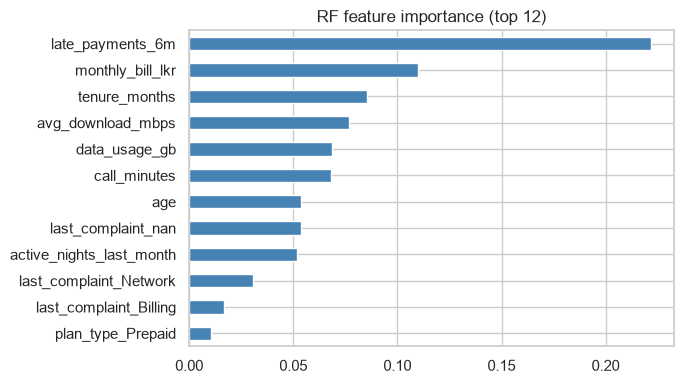

late_payments_6m            0.221763
monthly_bill_lkr            0.109698
tenure_months               0.085178
avg_download_mbps           0.076949
data_usage_gb               0.068669
call_minutes                0.068043
age                         0.053649
last_complaint_nan          0.053548
active_nights_last_month    0.051821
last_complaint_Network      0.030504
last_complaint_Billing      0.016741
plan_type_Prepaid           0.010412
dtype: float64

In [17]:
# feature importance from RF (after one-hot)
ohe = rf.named_steps["pre"].named_transformers_["cat"]
feat_names = list(ohe.get_feature_names_out(CAT)) + NUM
imp = rf.named_steps["clf"].feature_importances_

fi = pd.Series(imp, index=feat_names).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(7, 4))
fi[::-1].plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("RF feature importance (top 12)")
plt.tight_layout()
plt.show()
fi


## 7. Notes

RF and XGBoost are pretty close here. Late payments / tenure / bill / complaints matter most from the RF importances. Stacking helps a little.

Didn't do RF+ARIMA since this is binary churn, not a time series panel.

Run dashboard with:
```
python train_models.py
streamlit run app.py
```

In [18]:
# optional: dump models so the streamlit app can reuse the same fit
from pathlib import Path
import joblib, json

art = Path("artifacts")
art.mkdir(exist_ok=True)
joblib.dump(rf, art / "rf_pipeline.joblib")
joblib.dump(xgb, art / "xgb_pipeline.joblib")
joblib.dump(stack, art / "stack_pipeline.joblib")

# also kick the training script metrics file if you want the app charts
# (or just run: python train_models.py)
print("saved pipelines to artifacts/")


saved pipelines to artifacts/
